## DRQN with LSTM: Droplet Protocol Tracing and Reverse Engineering

This notebook implements a Deep Recurrent Q-Network (DRQN) with support for LSTM architectures for reverse-engineering droplet protocols on DMFBs. 

### Key Features:
- **LSTM**: Traditional recurrent memory for short-term dependencies
- **Episode-based replay**: Stores complete episodes for sequential learning
 
### Architecture Options:
1. **LSTM (Default)**: Fast, baseline with 256 hidden units

### References

```bibtex
@misc{hausknecht2017deeprecurrentqlearningpartially,
  title={Deep Recurrent Q-Learning for Partially Observable MDPs},
  author={Matthew Hausknecht and Peter Stone},
  year={2017},
  eprint={1507.06527},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  url={https://arxiv.org/abs/1507.06527},
}


## Import necessary libraries 

In [ ]:
# importing necessary libraries
import random
import time
import os 
import numpy as np
import torch
import torch.nn as nn
from collections import deque
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import pickle
import json 
import matplotlib.pyplot as plt
import gymnasium as gym
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import sys
sys.path.insert(0, os.path.abspath('../environment_utils'))

## DRQN Agent with LSTM Support

**DRQNagent** is an implementation of DRQN supporting a LSTM architectures.

### Architecture
- **Feature Extractor** → **LSTM** → **Fully-Connected Q-value Head**
- LSTM: 256 hidden units (default)

### Key Components
1. **Replay Buffer**: Episode-based storage (complete sequences)
2. **Network**: LSTM based network
3. **Training**: Standard DQN with episode sampling and target network updates

In [ ]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor

class DRQNagent:

    """
    Simplified Deep Recurrent Q-Network:
    - Store complete episodes in replay buffer
    - Train LSTM on full episode sequences
    - save trained agent as .zip file to desktop 
    - action_masking based on belief state map 
    """
    
    def __init__(self, 
                 env,                       
                 feature_extractor, 
                 action_dim, 
                 lstm_hidden_size=256,
                 gamma=0.99, 
                 lr=1e-4, 
                 batch_size=32, 
                 buffer_size=1000,
                 epsilon_start=1.0, 
                 epsilon_end=0.05, 
                 epsilon_decay=5000,
                 target_update=500, 
                 training_steps=10_000, 
                 tensorboard_dir=None,
                 run_name=None,
                 action_mask = False):
        
        self.env = env()
        self.feature_extractor_fn = feature_extractor
        self.action_dim = action_dim
        self.lstm_hidden_size = lstm_hidden_size
        self.gamma = gamma
        self.lr = lr
        self.batch_size = batch_size
        self.buffer_size = buffer_size
        self.epsilon_start = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update
        self.training_steps = training_steps
        self.action_mask = action_mask
        
        # running on CPU (current device is a macbook, change if needed)
        self.device = torch.device('cpu')

        # TensorBoard writer, save the train data to a chosen name (opens a folder)
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
            print(f"TensorBoard logging to: {tensorboard_dir}")
        else:
            self.writer = None

        # feature extractor network 
        feature_extractor = feature_extractor(self.env.observation_space)
        feat_dim = feature_extractor._features_dim
        
        # target and online networks 
        self.online_net = self._build_network(feature_extractor, feat_dim, lstm_hidden_size, action_dim)                                        # online network, trained through GD
        self.target_net = self._build_network(self.feature_extractor_fn(self.env.observation_space), feat_dim, lstm_hidden_size, action_dim)    # target network
        self.target_net.load_state_dict(self.online_net.state_dict())                                                                           # copies weights/biases from online to target
        self.target_net.eval()
        
        self.optimizer = torch.optim.Adam(self.online_net.parameters(), lr=lr)
        
        # Episode replay buffer - stores complete episodes
        self.replay_buffer = deque(maxlen=buffer_size)
        
        self.step_count = 0
        self.update_count = 0
        self.episode_count = 0
        
    def _build_network(self, feat_extractor, feat_dim, hidden_size, action_dim):

        class DRQNNet(nn.Module):

            """
            Creating network for DRQN
            """

            def __init__(
                    self, 
                    feat_extractor,
                    feat_dim, 
                    hidden_size, 
                    action_dim):
                
                super().__init__()


                self.feat_extractor = feat_extractor                                # extraction layer, CNN + MLP
                self.lstm = nn.LSTM(feat_dim, hidden_size, batch_first=True)        # recurrency layer
                self.fc = nn.Sequential(                                            # Q - Net
                    nn.Linear(hidden_size, 256),
                    nn.ReLU(),
                    nn.Linear(256, action_dim)
                )

            
            def forward(self, obs_dict, hidden=None):
                # obs_dict: {key: (batch, seq_len, ...)}
                B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                T = obs_dict[list(obs_dict.keys())[0]].shape[1]
                
                # Flatten to (B*T, ...)
                flat_obs = {k: v.reshape(B*T, *v.shape[2:]) for k, v in obs_dict.items()}
                features = self.feat_extractor(flat_obs)                 # (B*T, feat_dim)
                features = features.view(B, T, -1)                       # (B, T, feat_dim)
                
                lstm_out, hidden = self.lstm(features, hidden)           # (B, T, hidden_size)
                q_values = self.fc(lstm_out)                             # (B, T, action_dim)

                return q_values, hidden
        
        return DRQNNet(feat_extractor, feat_dim, hidden_size, action_dim)
    
    def get_epsilon(self):
        return self.epsilon_end + (self.epsilon_start - self.epsilon_end) * np.exp(-self.step_count / self.epsilon_decay) # epsilon decay over time steps 
    
    def select_action(self, obs_dict, info, hidden, epsilon):
        """
        Epsilon-greedy action selection, with optional action masking
        """
        # get action mask from info dict if available 
        mask = None 
        if self.action_mask: 
            mask = info.get("action_mask", None)
        
        # epsilon action selection
        if random.random() < epsilon: 
            if mask is None: 
                action = self.env.action_space.sample() 
            else: 
                valid_actions = np.where(np.array(mask) == 1)[0] 
                action = np.random.choice(valid_actions) 
            return action, hidden

        # greedy action selection
        with torch.no_grad():
            obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float().to(self.device) for k, v in obs_dict.items()}
            q_vals, new_hidden = self.online_net(obs_batch, hidden)
            q_vals = q_vals.squeeze(0).squeeze(0)

            if mask is not None:
                mask_tensor = torch.from_numpy(mask).to(self.device)
                q_vals = q_vals.masked_fill(mask_tensor == 0, -1e9)
            action = q_vals.argmax().item()

        return action, new_hidden

    def store_episode(self, episode):

        """Store complete episode: list of (obs, action, reward, next_obs, done)"""

        self.replay_buffer.append(episode)
    
    def sample_batch(self):
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        # Sample random episodes
        episodes = random.sample(self.replay_buffer, self.batch_size)

        return episodes
    
    def train_step(self):

        batch = self.sample_batch()
        if batch is None:
            return None
        
        total_loss = 0
        
        for episode in batch:
          
            obs_seq = []
            action_seq = []
            reward_seq = []
            next_obs_seq = []
            done_seq = []
            mask_seq = [] 

            for transition in episode:
                
                # support both action masking and non-masking transitions
                if len(transition) == 6:
                    obs, action, reward, next_obs, done, info = transition
                    mask_seq.append(info.get("action_mask", None))
                else:
                    obs, action, reward, next_obs, done = transition
                    mask_seq.append(None)
                
                obs_seq.append(obs)
                action_seq.append(action)
                reward_seq.append(reward)
                next_obs_seq.append(next_obs)
                done_seq.append(done)
            
            # Convert to tensors - shape: (1, T, ...)
            obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in obs_seq])).unsqueeze(0).float().to(self.device)
                        for k in obs_seq[0].keys()}
            next_obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in next_obs_seq])).unsqueeze(0).float().to(self.device)
                             for k in next_obs_seq[0].keys()}
            
            actions = torch.LongTensor(action_seq).unsqueeze(0).to(self.device)     # (1, T)
            rewards = torch.FloatTensor(reward_seq).unsqueeze(0).to(self.device)    # (1, T)
            dones = torch.FloatTensor(done_seq).unsqueeze(0).to(self.device)        # (1, T)
            

            hidden = None

            # Forward pass - current state Q-values
            q_values, hidden = self.online_net(obs_batch, hidden)        # (1, T, action_dim)
            q_values = q_values.squeeze(0)                  # (T, action_dim)
            current_q = q_values.gather(1, actions.squeeze(0).unsqueeze(1)).squeeze(1)  # (T,)

            # Compute target Q-values using next states
            with torch.no_grad():
                target_hidden = None
                next_q_values, target_hidden = self.target_net(next_obs_batch, target_hidden)          # (1, T, action_dim)
                next_q_values = next_q_values.squeeze(0)                    # (T, action_dim)
                
                if self.action_mask:
                    # Ensure all masks are present
                    assert all(m is not None for m in mask_seq), "Missing next-state action mask"
                    mask_tensor = torch.from_numpy(np.stack(mask_seq)).to(self.device)  # (T, action_dim)
                    next_q_values = next_q_values.masked_fill(mask_tensor == 0, -1e9)
                
                max_next_q = next_q_values.max(dim=1)[0]                    # (T,)
                target_q = rewards.squeeze(0) + self.gamma * max_next_q * (1 - dones.squeeze(0))
            
            # Loss
            loss = nn.functional.mse_loss(current_q, target_q)
            total_loss += loss.item()
            
            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.online_net.parameters(), 1.0)
            self.optimizer.step()
        
        return total_loss / len(batch)
    
    def train(self):
        
        # Track rolling average for smoother logging
        episode_return_window = deque(maxlen=100)
        episode_normalized_return_window = deque(maxlen=100)

        
        # progress bar 
        with tqdm(total=self.training_steps, desc="Training Progress", unit="step") as pbar:

            print("\n ________________________________ training DRQN agent _________________________________\n")

            while self.step_count < self.training_steps:

                # Collect one episode
                obs, _ = self.env.reset()
                done = False
                info = {}
                episode = []
                episode_return = 0
                hidden = None
                episode_steps = 0
                
                while not done:
                    epsilon = self.get_epsilon()
                    action, hidden = self.select_action(obs, info, hidden, epsilon)
                    next_obs, reward, terminated, truncated, info = self.env.step(action)
                    done = terminated or truncated
                    
                    # Store transition 
                    episode.append((obs, action, reward, next_obs, done, info) if self.action_mask else (obs, action, reward, next_obs, done))
                    episode_return += reward
                    obs = next_obs
                    self.step_count += 1
                    episode_steps += 1

                pbar.update(episode_steps)

                # Store episode
                self.store_episode(episode)
                self.episode_count += 1
                episode_return_window.append(episode_return)
                
                normalized_return = episode_return / episode_steps if episode_steps > 0 else 0
                episode_normalized_return_window.append(normalized_return)

                # Log to TensorBoard
                if self.writer:
                    self.writer.add_scalar('rollout/ep_rew_mean', np.mean(episode_return_window), self.step_count)
                    self.writer.add_scalar('rollout/ep_len_mean', episode_steps, self.step_count)
                    self.writer.add_scalar('rollout/epsilon', epsilon, self.step_count)
                    self.writer.add_scalar('train/episode_reward', episode_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return', normalized_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return_mean', np.mean(episode_normalized_return_window), self.step_count)
                
                # Train
                loss = None
                if len(self.replay_buffer) >= self.batch_size:
                    loss = self.train_step()
                    self.update_count += 1
                    
                    # Log training metrics
                    if self.writer and loss is not None:
                        self.writer.add_scalar('train/loss', loss, self.update_count)
                    
                    # Update target network
                    if self.update_count % self.target_update == 0:
                        self.target_net.load_state_dict(self.online_net.state_dict())
        
        # Close TensorBoard writer
        if self.writer:
            log_dir = self.writer.log_dir
            self.writer.close()
            print(f"\nTensorBoard logs saved to: {log_dir}")
            print(f"To view: tensorboard --logdir={log_dir}")
        
        print("________________ training complete _________________ \n")
    
    def save_complete(self, filepath):
        """
        Save complete agent (SB3-style) - can reconstruct from scratch
        Saves to .pkl file containing everything needed to rebuild agent
        """

        save_dict = {
            # Model weights
            'online_net_state_dict': self.online_net.state_dict(),
            'target_net_state_dict': self.target_net.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            
            # Training state
            'step_count': self.step_count,
            'episode_count': self.episode_count,
            'update_count': self.update_count,
            
            # Complete hyperparameters 
            'init_params': {
                'action_dim': self.action_dim,
                'lstm_hidden_size': self.lstm_hidden_size,
                'gamma': self.gamma,
                'lr': self.lr,
                'batch_size': self.batch_size,
                'buffer_size': self.buffer_size,
                'epsilon_start': self.epsilon_start,
                'epsilon_end': self.epsilon_end,
                'epsilon_decay': self.epsilon_decay,
                'target_update': self.target_update,
                'training_steps': self.training_steps,
            },
        }
        
        # Change extension to .pkl for complete save
        if not filepath.endswith('.pkl'):
            filepath = filepath.replace('.pth', '.pkl')
        
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"Complete agent saved to: {filepath}")
        print(f"File contains all hyperparameters - can reconstruct agent from scratch")
    
    @classmethod
    def load_complete(cls, filepath, env_constructor, feature_extractor_constructor):
        """
        Load complete agent (SB3-style) - reconstructs from saved hyperparameters
        
        Args:
            filepath: Path to .pkl file
            env_constructor: Environment constructor (lambda: YourEnv())
            feature_extractor_constructor: Feature extractor constructor (lambda obs_space: CustomFeatureExtractor(obs_space))
        
        Returns:
            Loaded agent instance
        """
        
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        # Reconstruct agent with saved hyperparameters
        init_params = save_dict['init_params']
        agent = cls(
            env=env_constructor,
            feature_extractor=feature_extractor_constructor,
            **init_params  # saved hyperparameters used
        )
        
        # Load weights and training state
        agent.online_net.load_state_dict(save_dict['online_net_state_dict'])
        agent.target_net.load_state_dict(save_dict['target_net_state_dict'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state_dict'])
        agent.step_count = save_dict['step_count']
        agent.episode_count = save_dict['episode_count']
        agent.update_count = save_dict['update_count']
        
        print(f"Complete agent loaded from: {filepath}")
        print(f"Trained for {agent.step_count} steps, {agent.episode_count} episodes")

        return agent

## Train Agent

Train agent with own hyperparameters:

**TensorBoard Logging:**
- `rollout/ep_rew_mean`: Average episode reward (last 100)
- `rollout/ep_len_mean`: Average episode length (last 100)
- `rollout/normalized_return`: Reward per step (per episode)
- `rollout/normalized_return_mean`: Average normalized return (last 100)
- `rollout/epsilon`: Exploration rate
- `train/loss`: TD loss
- `train/episode_reward`: Current episode reward

**Run TensorBoard:** `tensorboard --logdir models/tensorboard`

In [3]:
# Get action space dimension
env_instance = VoltageDistributionEnv()
action_dim = env_instance.action_space.n
print(f"The total action dimensions are: {action_dim}")

The total action dimensions are: 324


### Option 1: Train LSTM Agent

Traditional recurrent architecture with n hidden units. 

In [6]:
LSTMagent = DRQNagent(
    # Environment and Architecture
    env=lambda: VoltageDistributionEnv(),                              # create environment instance
    feature_extractor=lambda obs_space: CustomFeatureExtractor(obs_space),  # feature extractor 
    action_dim = action_dim,                                                    # Number of discrete actions (N x N grid) 
    lstm_hidden_size=256,                                              # LSTM hidden state dimension (memory capacity)
    
    # Training Hyperparameters
    gamma=0.9,                                                        # Discount factor (how much to value future rewards)
    lr=1e-4,                                                           # Learning rate for Adam optimizer
    batch_size=32,                                                     # Number of episodes sampled per training update
    buffer_size=1_000,                                                # Replay buffer capacity (max episodes stored)
    
    # Exploration Strategy (Epsilon-Greedy)
    epsilon_start=1.0,                                                 # Initial exploration rate (100% random actions)
    epsilon_end=0.001,                                                 # Final exploration rate (n% random, n% greedy)
    epsilon_decay=5_000,                                               # Steps over which epsilon decays exponentially
    
    # Network Updates
    target_update=500,                                                 # Frequency (in updates) to sync target network with online network
    
    # Training Schedule
    training_steps=100_000,                                             # Total environment steps to train 
    
    # TensorBoard Logging
    tensorboard_dir='../models/tensorboard',                             # Root directory for all TensorBoard logs
    run_name='RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2',                                       # Unique run identifier (creates subfolder for this experiment)

    # action masking
    action_mask=False                                                  # Enable action masking 
)

LSTMagent.train()
LSTMagent.save_complete('../models/RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2.pkl')

TensorBoard logging to: models/tensorboard/RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2


Training Progress:   0%|          | 130/100000 [00:00<01:36, 1034.72step/s]


 ________________________________ training DRQN agent _________________________________



Training Progress: 100016step [23:35, 70.67step/s]                         


TensorBoard logs saved to: models/tensorboard/RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2
To view: tensorboard --logdir=models/tensorboard/RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2
________________ training complete _________________ 

Complete agent saved to: models/RecurrentDQN_Finalized_11x11_V1_no_action_mask_PT2.pkl
File contains all hyperparameters - can reconstruct agent from scratch


In [4]:
with open('../configuration/grid_configuration.json', 'r') as f:
    config = json.load(f)

# Access values
grid_size = config['gridSize']
electrode_positions = config['electrode_positions']
obstacles = config['obstacles']
obstacle_set = set(tuple(obs) for obs in obstacles)

# All grid positions (action space is now full grid)
all_grid_positions = [(i, j) for i in range(grid_size) for j in range(grid_size)]

%matplotlib inline
def extract_qvalues(model, obs_dict, hidden=None):

    """Extract Q-values for given observation using the trained model"""
    
    with torch.no_grad():
        obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float() 
                     for k, v in obs_dict.items()}
        q_vals, new_hidden = model.online_net(obs_batch, hidden)
        q_values = q_vals.squeeze()
        
        return q_values.cpu().numpy(), new_hidden

def plot_qvalues_heatmap(q_values, action_mask=None, model=None):

    """
    Plot heatmap of Q-values over the full grid action space.
    Masked (invalid) actions are shown as white (NaN) cells with red X markers.
    Electrodes are marked with white borders.
    """

    plt.figure(figsize=(10, 8))
    q_grid = np.full((grid_size, grid_size), np.nan)

    # Action space is full grid: action idx = row * grid_size + col
    for idx in range(grid_size * grid_size):
        row = idx // grid_size
        col = idx % grid_size
        # Mask invalid actions for visualization
        if action_mask is not None and action_mask[idx] == 0:
            q_grid[row, col] = np.nan
        else:
            q_grid[row, col] = q_values[idx]
    
    # Find best valid action (considering mask if provided)
    if action_mask is not None:
        valid_indices = np.where(action_mask == 1)[0]
        if len(valid_indices) > 0:
            valid_q_values = q_values[valid_indices]
            max_q_idx = valid_indices[np.argmax(valid_q_values)]
        else:
            max_q_idx = np.argmax(q_values)
    else:
        max_q_idx = np.argmax(q_values)
    
    # Convert action index to row/col
    max_row = max_q_idx // grid_size
    max_col = max_q_idx % grid_size

    # Set white background for NaN values
    cmap = plt.cm.viridis.copy()
    cmap.set_bad(color='white')

    plt.imshow(q_grid, cmap=cmap, interpolation='nearest', origin='upper')
    plt.colorbar(label='Q-value')
    
    # Highlight masked (invalid) actions with red X if action masking is used
    if action_mask is not None:
        for idx in range(grid_size * grid_size):
            if action_mask[idx] == 0:
                row = idx // grid_size
                col = idx % grid_size
                plt.plot(col, row, 'rx', markersize=8, markeredgewidth=1.5)
    
    # Draw white borders around electrodes to show their positions
    for electrode in electrode_positions:
        electrode_row, electrode_col = electrode[0], electrode[1]
        rect = plt.Rectangle((electrode_col - 0.5, electrode_row - 0.5), 1, 1, 
                             linewidth=2, edgecolor='white', facecolor='none')
        plt.gca().add_patch(rect)
    
    # Red rectangle around best action
    rect = plt.Rectangle((max_col - 0.5, max_row - 0.5), 1, 1, linewidth=3, edgecolor='red', facecolor='none')
    plt.gca().add_patch(rect)
    
    title = 'Q-values Heatmap over Full Grid'
    if action_mask is not None:
        num_valid = int(action_mask.sum())
        title += f' (Masking: {num_valid}/{len(action_mask)} valid)'
    plt.title(title)
    plt.xlabel('Column')
    plt.ylabel('Row')
    plt.show()

def main(model_path, episodes, render_delay, use_action_masking=False): 
    """main renderer loop for trained agent"""
    
    from IPython.display import clear_output
    env = VoltageDistributionEnv(render_mode='human')
    
    episode_summaries = []
    
    for ep in range(episodes):
        obs, info = env.reset()
        done = False
        hidden = None
        total_reward = 0
        step_num = 0
        
        while not done:
            clear_output(wait=True)
            
            # Get Q-values for action selection
            q_values, hidden = extract_qvalues(model_path, obs, hidden)
            
            # Get action mask from info dict (environment provides it)
            action_mask = info.get('action_mask', None) if use_action_masking else None
            
            # Select action (respecting mask if provided)
            if action_mask is not None:
                valid_indices = np.where(action_mask == 1)[0]
                if len(valid_indices) > 0:
                    valid_q_values = q_values[valid_indices]
                    max_valid_idx = np.argmax(valid_q_values)
                    action = valid_indices[max_valid_idx]
                else:
                    action = np.argmax(q_values)
            else:
                action = np.argmax(q_values)
            
            # Take action in environment
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Render environment and visualizations
            env.render()
            plot_qvalues_heatmap(q_values, action_mask=action_mask, model=model_path)
            
            time.sleep(render_delay)
            
            total_reward += reward
            obs = next_obs
            step_num += 1
        
        summary = f"Episode {ep+1} | Total Reward: {total_reward:.2f} | Steps: {len(env._droplet_path)}"
        episode_summaries.append(summary)
    
    for entry in episode_summaries:
        print(entry)
    
    env.close()
    plt.close()

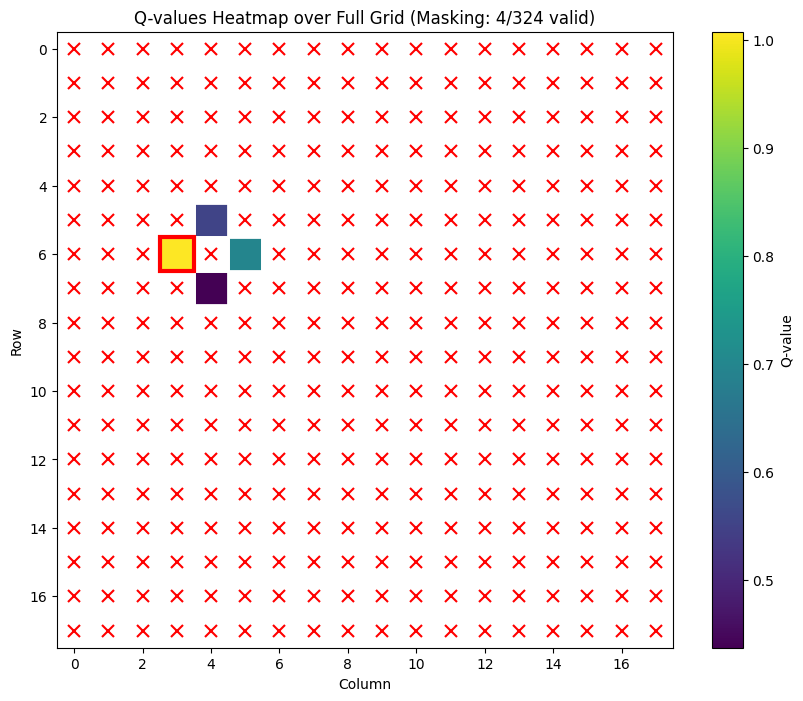

Episode 1 | Total Reward: 44.37 | Steps: 56


In [7]:
# Load trained agent
loaded_agent = DRQNagent.load_complete(
    '../models/RecurrentDQN_Finalized_SCIBOT_V1.pkl',  # Change to your model path
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

# Run visualization
main(loaded_agent, episodes=1, render_delay=0.2, use_action_masking=True)

## Multipass Search Refinement

**Refine action masks as protocol is repeated up to n times, using previous information to assist with current decisions**

In [5]:
class MultipassEnvWrapper(gym.Wrapper):
    """
    Wrapper ensures same protocol is repeated across passes.

    - Pass 1: Let env generate protocol, store _droplet_path
    - Pass 2+: Override _droplet_path with previously generated protocol
    - Injects refined masks from PassBasedMasking using three-stage refinement
    
    """
    
    def __init__(self, env, pass_based_masking, pass_num, stored_protocol=None):
        super().__init__(env)
        self.pass_based_masking = pass_based_masking
        self.pass_num = pass_num
        self.stored_protocol = stored_protocol
        self.timestep = 0
        self.grid_size = env.size
    
    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        
        # For passes greater than 1, override droplet path with stored protocol
        if self.stored_protocol is not None and self.pass_num > 1:
            self.env._droplet_path = self.stored_protocol.copy()
            self.env._droplet_path_index = 0
            self.env._droplet_location = self.env._droplet_path[0]
            self.env.end_pos = self.env._droplet_path[-1]
            self.env.length = len(self.env._droplet_path)
            
            # Recalculate voltage grid for starting position
            from helper_functions import voltage_grid as calc_voltage_grid
            self.env._voltage_grid = calc_voltage_grid(
                self.env._droplet_location,
                self.env.belief.sigma,
                obstacles,
                self.grid_size
            )
            
            # Get refined action mask for timestep 0 using previous pass data
            current_mask = info['action_mask']
            refined_mask = self.pass_based_masking.get_refined_mask(timestep=0, current_belief_mask=current_mask)
            info['action_mask'] = refined_mask
        
        self.timestep = 0
        self.pass_based_masking.start_new_episode()
        
        return obs, info
    
    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        
        # Extract data for recording
        probe_position = (action // self.grid_size, action % self.grid_size)
        emf = obs['voltage'][0]
        corrected_belief = info.get('filtered_belief', None)
        
        if corrected_belief is not None:
            self.pass_based_masking.record_step(self.timestep, probe_position, emf, corrected_belief)
        
        self.timestep += 1
        
        # For Pass 2+, override action mask with refined mask
        if self.pass_num > 1:
            current_mask = info.get('action_mask', None)
            if current_mask is not None:
                refined_mask = self.pass_based_masking.get_refined_mask(self.timestep, current_mask)
                info['action_mask'] = refined_mask
        
        if terminated or truncated:
            self.pass_based_masking.end_episode()
        
        return obs, reward, terminated, truncated, info
    
    def get_stored_protocol(self):
        """Get droplet path to reuse in subsequent passes."""
        return self.env._droplet_path.copy()

In [ ]:
class PassBasedMasking:
    """
    Three-stage belief refinement for multipass protocol reconstruction.
    
    Stage 1: Historical Belief Constraint
        - Use corrected belief from previous pass at each timestep
        - If belief was 0 at a location, it stays 0 for current pass as well 
        
    Stage 2: Global Smoothing
        - Propagate constraints from all known locations both forward and backward in time
        - Forward propagation: reachable from known past locations
        - Backward propagation: can reach known future locations
        
    Stage 3: Ensure Decrease in Valid Locations 
        - Number of valid locations never increases pass over pass
        - If current refinement has more locations than previous pass, use previous
    
    Key principle: Belief only shrinks or stays same, never expands.
    """
    
    def __init__(self, grid_size):
        self.grid_size = grid_size
        self.num_states = grid_size * grid_size
        
    
        self.current_trajectory = []   # Current
        self.previous_trajectory = []  # Previous  
        
        self.neighbor_map = self._build_neighbor_map()
    
    def _build_neighbor_map(self):
        """Build adjacency graph for transition model (N/E/S/W moves)."""
        neighbor_map = {}
        for idx in range(self.num_states):
            row, col = self._idx_to_pos(idx)
            neighbors = []
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nr, nc = row + dr, col + dc
                if 0 <= nr < self.grid_size and 0 <= nc < self.grid_size:
                    neighbors.append(nr * self.grid_size + nc)
            neighbor_map[idx] = neighbors
        return neighbor_map
    
    def _get_neighbors(self, pos):
        """Get 4-connected neighbors (N/E/S/W) of a position."""
        row, col = pos
        neighbors = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = row + dr, col + dc
            if 0 <= nr < self.grid_size and 0 <= nc < self.grid_size:
                neighbors.append((nr, nc))
        return neighbors
    
    def _pos_to_idx(self, pos):
        """Convert (row, col) to action index."""
        return pos[0] * self.grid_size + pos[1]
    
    def _idx_to_pos(self, idx):
        """Convert action index to (row, col)."""
        return (idx // self.grid_size, idx % self.grid_size)
    
    def record_step(self, timestep, probe_position, emf, corrected_belief):
        """
        Record a single step's data during episode.
        
        Args:
            timestep: Current timestep
            probe_position: (row, col) tuple of probe location
            emf: EMF reading at probe position
            corrected_belief: Full belief distribution AFTER correction step (np.ndarray)
        """
        self.current_trajectory.append({
            't': timestep,
            'pos': probe_position,
            'emf': emf,
            'belief': corrected_belief.copy()  
        })
    
    def start_new_episode(self):
        """Move current trajectory to previous, start fresh recording."""
        self.previous_trajectory = self.current_trajectory
        self.current_trajectory = []
    
    def end_episode(self):
        """Mark end of current episode (placeholder for future use)."""
        pass
    
    def get_refined_mask(self, timestep, current_belief_mask):
        """
        Compute refined mask using three-stage refinement.
        
        Args:
            timestep: Current timestep
            current_belief_mask: Mask from current Bayesian belief (from env), shape (num_states,)
        
        Returns:
            Refined action mask (np.ndarray of shape (num_states,))
        """

        if len(self.previous_trajectory) == 0:
            return current_belief_mask
        
        # ensure current mask is 1D
        current_belief_mask = np.array(current_belief_mask).flatten()
        
        traj_by_t = {step['t']: step for step in self.previous_trajectory}
        
        if timestep not in traj_by_t:
            return current_belief_mask
        
        # get historical belief and flatten to 1D if needed
        historical_belief = traj_by_t[timestep]['belief']
        historical_belief = np.array(historical_belief).flatten()
        
        historical_threshold = (1.0 / self.num_states) * 0.1  # Matches env threshold
        historical_mask = (historical_belief >= historical_threshold).astype(np.int32)
        
        refined_mask = current_belief_mask * historical_mask
    
        known_locations = {}  
        for step in self.previous_trajectory:
            if step['emf'] >= 0.999:
                known_locations[step['t']] = self._pos_to_idx(step['pos'])
        
        smoothing_mask = self._global_smoothing(timestep, known_locations)
        
        refined_mask = refined_mask * smoothing_mask
        
        
        refined_count = refined_mask.sum()
        historical_count = historical_mask.sum()
        
        if refined_count > historical_count:
            refined_mask = historical_mask.copy()
        
        if refined_mask.sum() == 0:
            refined_mask = historical_mask.copy()
            if refined_mask.sum() == 0:
                refined_mask = current_belief_mask.copy()
        
        return refined_mask.astype(np.int32)
    
    def _global_smoothing(self, timestep, known_locations):

        """
        Apply global smoothing using transition model.
        
        For each known location (EMF=1), propagate reachability constraints:
        - Forward: cells reachable from past known location
        - Backward: cells that can reach future known locations
        
        Args:
            timestep: Target timestep to compute mask for
            known_locations: Dict {timestep: position_idx} for EMF=1 locations
        
        Returns:
            Smoothing constraint mask (np.ndarray)
        """
        if len(known_locations) == 0:
            return np.ones(self.num_states, dtype=np.int32)
        
        forward_mask = np.ones(self.num_states, dtype=np.int32)
        backward_mask = np.ones(self.num_states, dtype=np.int32)
        
        past_known = [(t, idx) for t, idx in known_locations.items() if t < timestep]
        
        if past_known:
            closest_past_t, closest_past_idx = max(past_known, key=lambda x: x[0])
            steps_forward = timestep - closest_past_t
            
            forward_mask = self._propagate_n_steps({closest_past_idx}, steps_forward)
        
        future_known = [(t, idx) for t, idx in known_locations.items() if t > timestep]
        
        if future_known:
            closest_future_t, closest_future_idx = min(future_known, key=lambda x: x[0])
            steps_backward = closest_future_t - timestep
            
            backward_mask = self._propagate_n_steps({closest_future_idx}, steps_backward)
        
        if timestep in known_locations:
            exact_mask = np.zeros(self.num_states, dtype=np.int32)
            exact_mask[known_locations[timestep]] = 1
            return exact_mask
        
        smoothing_mask = forward_mask * backward_mask
        
        return smoothing_mask
    
    def _propagate_n_steps(self, start_positions, n_steps):
        """
        Compute all cells reachable from start_positions in exactly n_steps.
        
        Uses BFS-style propagation through transition model.
        
        Args:
            start_positions: Set of starting position indices
            n_steps: Number of transition steps
        
        Returns:
            Mask of reachable positions (np.ndarray)
        """
        if n_steps == 0:
            mask = np.zeros(self.num_states, dtype=np.int32)
            for idx in start_positions:
                mask[idx] = 1
            return mask
    
        current_set = start_positions.copy()

        for _ in range(n_steps):
            next_set = set()
            for idx in current_set:
                for neighbor_idx in self.neighbor_map[idx]:
                    next_set.add(neighbor_idx)
            current_set = next_set
        
        # Convert to mask
        mask = np.zeros(self.num_states, dtype=np.int32)
        for idx in current_set:
            mask[idx] = 1
        
        return mask

In [ ]:
def run_multipass_protocol(agent, num_passes=3, render=False, render_delay=0.5):
    """
    Run same protocol multiple times with iterative mask refinement.
    
    Uses PassBasedMasking with three-stage refinement:
    1. Historical belief constraint
    2. Global smoothing
    3. belief space decrease constraint 
    
    Args:
        agent: Trained DRQNagent
        num_passes: Number of passes (default 3)
        render: Whether to render environment
        render_delay: Delay between steps when rendering
    
    Returns:
        results: List of dicts per pass with reward, steps, mask_sizes, entropy
    """
    from IPython.display import clear_output
    
    # Load grid config
    with open('../configuration/grid_configuration.json', 'r') as f:
        grid_config = json.load(f)
    grid_size = grid_config['gridSize']
    
    # Shared masking logic across passes
    pass_based_masking = PassBasedMasking(grid_size)
    results = []
    stored_protocol = None
    
    for pass_num in range(1, num_passes + 1):
        
        # Create wrapped environment
        base_env = VoltageDistributionEnv(render_mode='human' if render else None)
        env = MultipassEnvWrapper(base_env, pass_based_masking, pass_num, stored_protocol)
        
        # Reset
        obs, info = env.reset()
        hidden = None  # LSTM hidden state
        
        # Store protocol from first pass
        if pass_num == 1:
            stored_protocol = env.get_stored_protocol()
        
        # Episode loop
        done = False
        total_reward = 0
        step_num = 0
        mask_sizes = []
        entropy_values = []  # Track entropy at each step
        
        while not done:
            if render:
                clear_output(wait=True)
            
            # Get action mask
            action_mask = info.get('action_mask', None)
            if action_mask is not None:
                mask_sizes.append(int(np.sum(action_mask)))
            
            # Track belief entropy
            current_entropy = env.env.belief.get_state_entropy()
            entropy_values.append(current_entropy)
            
            # Get Q-values from agent
            q_values, hidden = extract_qvalues(agent, obs, hidden)
            
            # Select action (greedy over valid actions)
            if action_mask is not None:
                valid_indices = np.where(np.array(action_mask) == 1)[0]
                if len(valid_indices) > 0:
                    action = valid_indices[np.argmax(q_values[valid_indices])]
                else:
                    action = np.argmax(q_values)
            else:
                action = np.argmax(q_values)
            
            # Render
            if render:
                env.render()
                pos = (action // grid_size, action % grid_size)
                print(f"Pass {pass_num} | Step {step_num} | Pos: {pos} | EMF: {obs['voltage'][0]:.3f} | Mask: {mask_sizes[-1] if mask_sizes else 'N/A'} | Entropy: {current_entropy:.3f}")
                plot_qvalues_heatmap(q_values, action_mask=action_mask, model=agent)
                time.sleep(render_delay)
            
            # Step
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            step_num += 1
        
        # Compute metrics
        avg_mask = np.mean(mask_sizes) if mask_sizes else 0
        avg_entropy = np.mean(entropy_values) if entropy_values else 0
        final_entropy = entropy_values[-1] if entropy_values else 0
        normalized_return = total_reward / len(mask_sizes) if mask_sizes else 0
        
        result = {
            'pass_num': pass_num,
            'reward': total_reward,
            'normalized_return': normalized_return,
            'steps': len(mask_sizes),
            'mask_sizes': mask_sizes,
            'avg_mask_size': avg_mask,
            'entropy_values': entropy_values,
            'avg_entropy': avg_entropy,
            'final_entropy': final_entropy
        }
        results.append(result)
        
        env.close()
    
    # Summary table
    print("="*65)
    print(f"{'Pass':<6} {'Reward':<10} {'Norm Return':<12} {'Avg Entropy':<12} {'Avg Mask':<10} {'Steps':<8}")
    print("-"*65)
    for r in results:
        print(f"{r['pass_num']:<6} {r['reward']:<10.2f} {r['normalized_return']:<12.3f} {r['avg_entropy']:<12.3f} {r['avg_mask_size']:<10.1f} {r['steps']:<8}")
    
    return results, stored_protocol



## Run Multipass Protocol Refinement

Load trained agent and run 3 passes of the same protocol with iterative mask refinement.

In [8]:
# Load trained agent
loaded_agent = DRQNagent.load_complete(
    '../models/RecurrentDQN_Finalized_SCIBOT_V1.pkl',
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

results, stored_protocol = run_multipass_protocol(
    loaded_agent, 
    num_passes=1, 
    render=False, 
    render_delay=0.1,
)

Complete agent loaded from: models/RecurrentDQN_Finalized_SCIBOT_V1.pkl
Trained for 100015 steps, 2239 episodes
Pass   Reward     Norm Return  Avg Entropy  Avg Mask   Steps   
-----------------------------------------------------------------
1      28.92      0.741        0.118        26.8       39      


In [ ]:
# Simple Multipass Data Collection
# Change model path and run. Manually change sigma in grid_configuration.json first.

import pandas as pd
loaded_agent = DRQNagent.load_complete(
    '../models/RecurrentDQN_Finalized_SCIBOT_V1.pkl', 
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

all_data = []
for i in range(30):
    results, stored_protocol = run_multipass_protocol(loaded_agent, num_passes=3, render=False, render_delay=0.0)
    
    for r in results:
        all_data.append({
            'pass': r['pass_num'],
            'normalized_return': r['normalized_return'],
            'avg_entropy': r['avg_entropy'],
            'avg_mask_size': r['avg_mask_size']
        })
    
    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/30")

df = pd.DataFrame(all_data)
df.to_csv('11x11_V2.csv', index=False) 

grouped = df.groupby('pass')
for pass_num in sorted(df['pass'].unique()):
    data = grouped.get_group(pass_num)
    print(f"\nPass {pass_num}:")
    print(f"  Normalized Return: {data['normalized_return'].mean():.3f} ± {data['normalized_return'].std():.3f}")
    print(f"  Avg Entropy:       {data['avg_entropy'].mean():.3f} ± {data['avg_entropy'].std():.3f}")
    print(f"  Avg Mask Size:     {data['avg_mask_size'].mean():.1f} ± {data['avg_mask_size'].std():.1f}")

Complete agent loaded from: models/RecurrentDQN_Finalized_SCIBOT_V1.pkl
Trained for 100015 steps, 2239 episodes
Pass   Reward     Norm Return  Avg Entropy  Avg Mask   Steps   
-----------------------------------------------------------------
1      32.34      0.735        0.100        19.1       44      
2      42.28      0.961        0.053        8.4        44      
3      43.05      0.978        0.031        1.2        44      
Pass   Reward     Norm Return  Avg Entropy  Avg Mask   Steps   
-----------------------------------------------------------------
1      19.20      0.640        0.197        42.3       30      
2      28.03      0.934        0.098        12.7       30      
3      28.03      0.934        0.098        10.9       30      
Pass   Reward     Norm Return  Avg Entropy  Avg Mask   Steps   
-----------------------------------------------------------------
1      25.08      0.716        0.118        22.7       35      
2      33.28      0.951        0.067        10.3  

**Make 3d line plot for visualization of path over time**

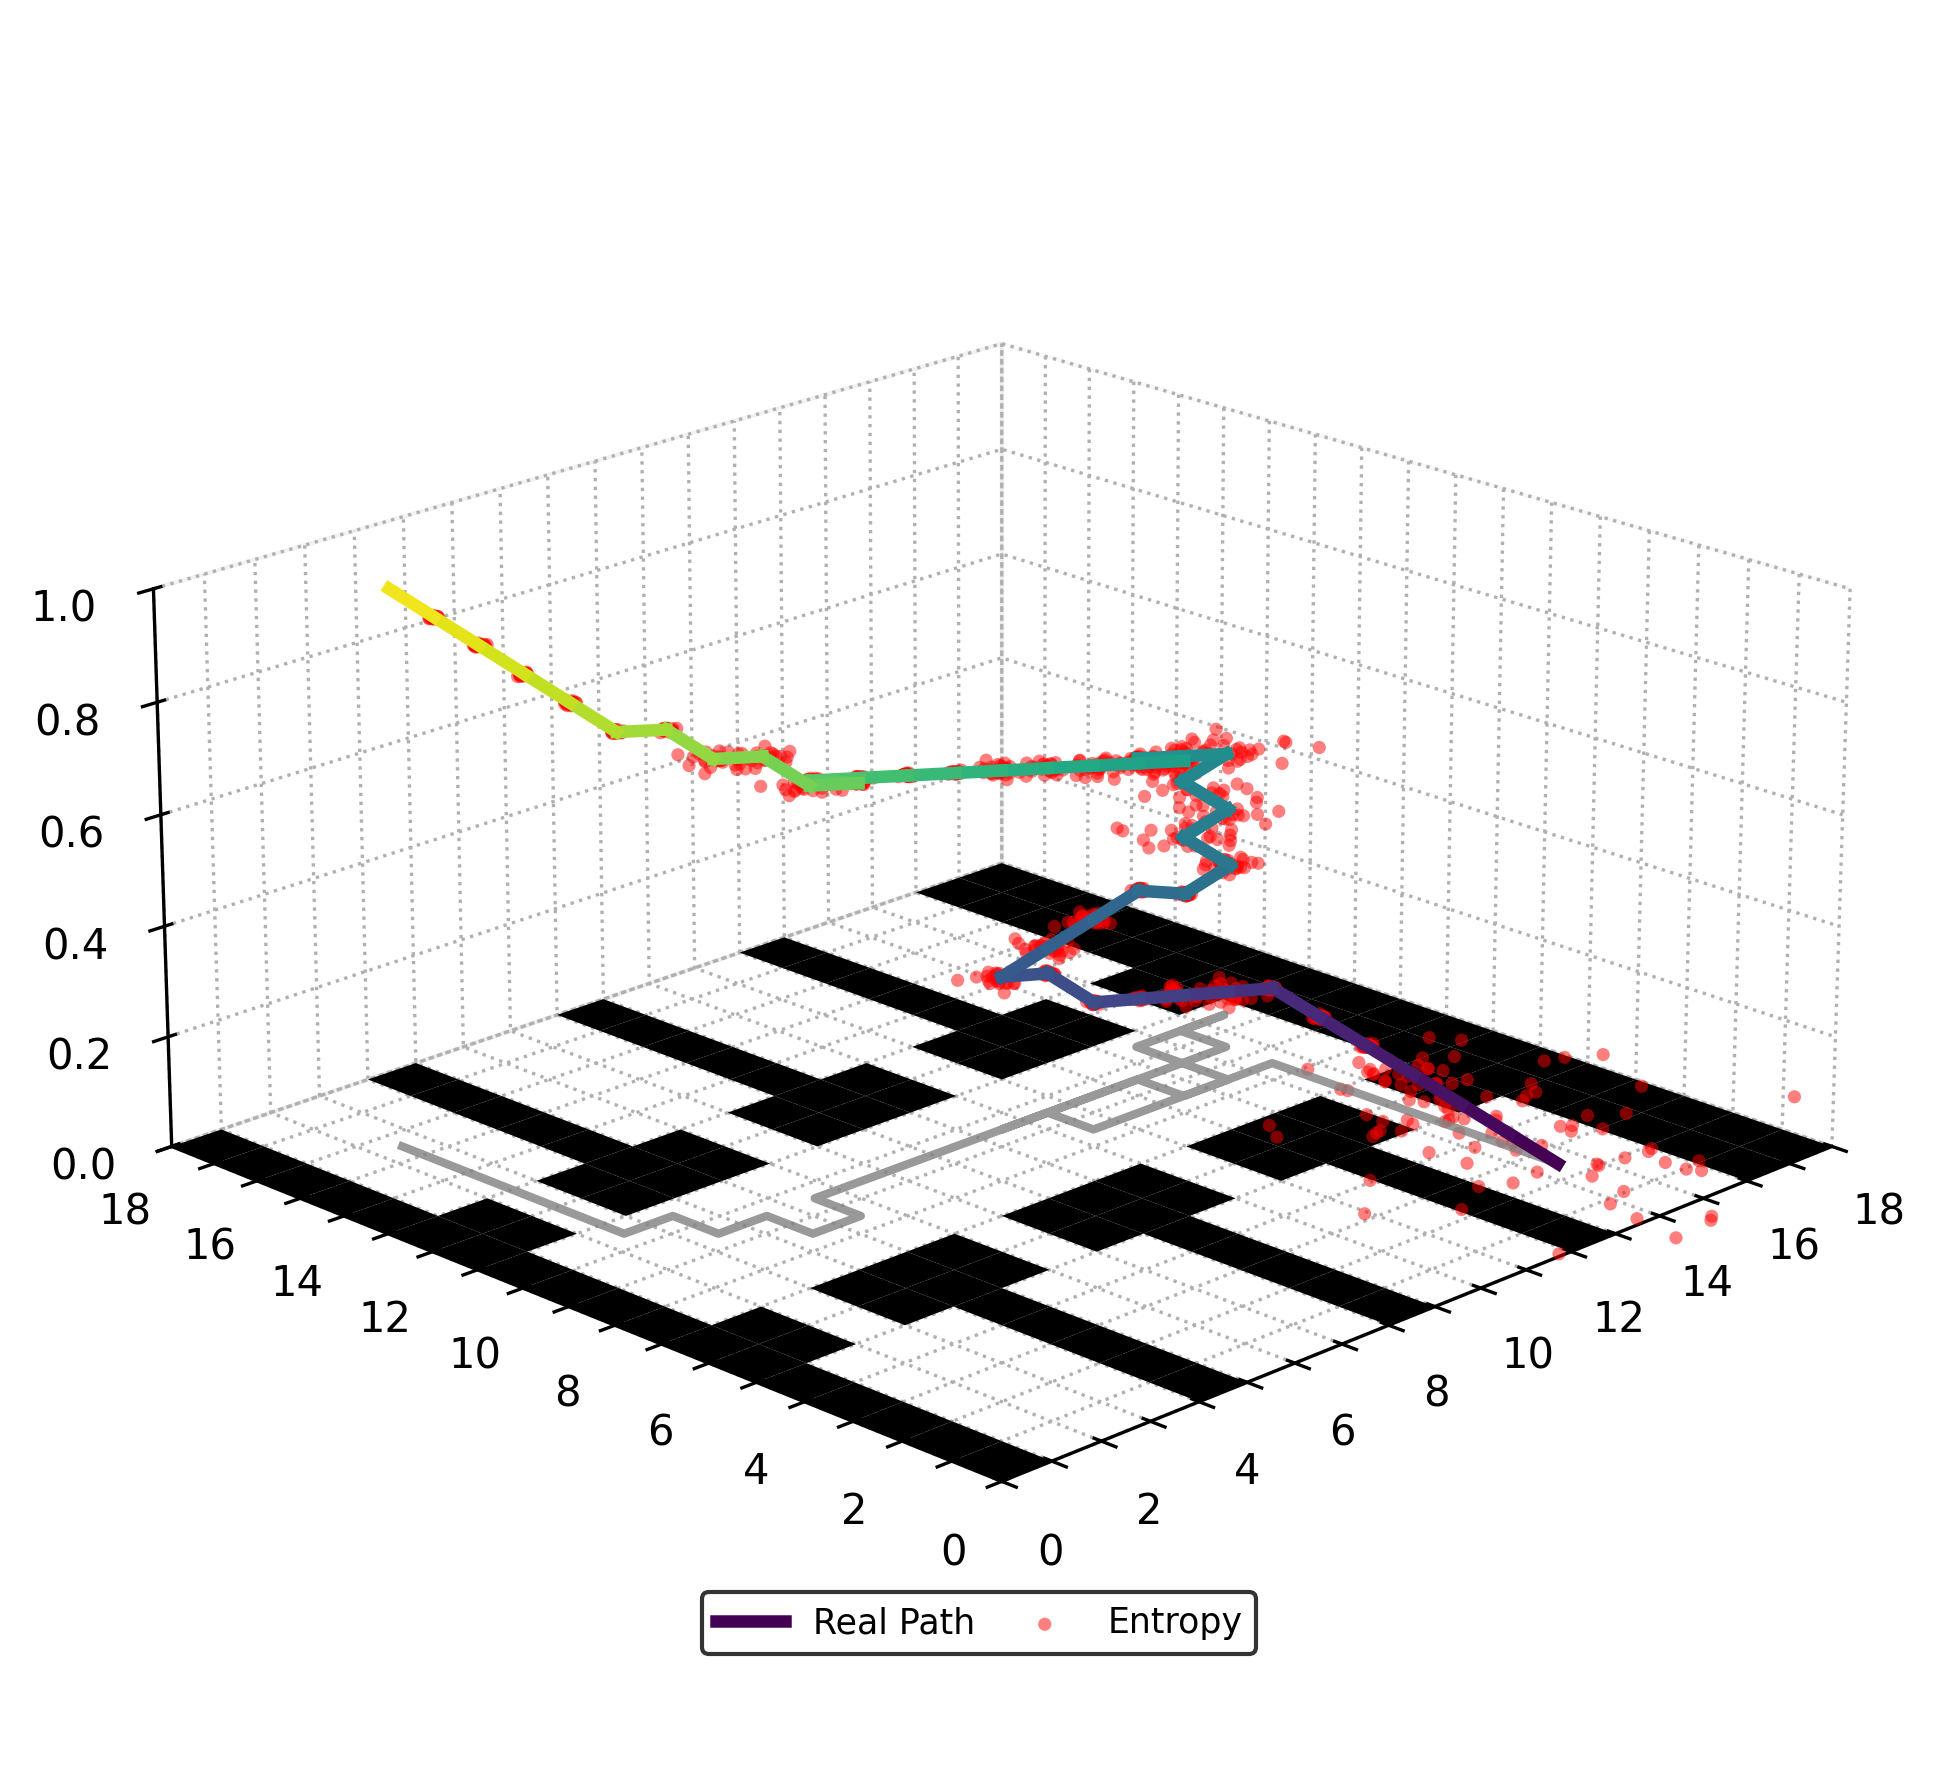

In [182]:
true_path = stored_protocol
x = [pos[0] for pos in true_path]
y = [pos[1] for pos in true_path]

# visualization 
fig = plt.figure(figsize=(10, 6), dpi=300)
ax = fig.add_subplot(111, projection="3d")

ax.set_xticks(np.arange(0, grid_size +1, 1))
ax.set_xticklabels([str(i) if i % 2 == 0 else "" for i in range(grid_size +1 )])
ax.set_yticks(np.arange(0, grid_size +1, 1))
ax.set_yticklabels([str(i) if i % 2 == 0 else "" for i in range(grid_size +1)])
ax.set_xlim(0, grid_size)
ax.set_ylim(0, grid_size)
ax.set_zlim(0, 1)

ax.set_box_aspect((1, 1, 0.5))
ax.view_init(elev=20, azim=-135)

ax.grid(True)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis._axinfo["grid"]["linestyle"] = ":"
    axis._axinfo["grid"]["linewidth"] = 0.8

ax.computed_zorder = False
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

for r, c in obstacles:
    verts = [[(r, c, 0), (r+1, c, 0), (r+1, c+1, 0), (r, c+1, 0)]]
    ax.add_collection3d(Poly3DCollection(verts, facecolors='black', alpha=1.0))

t = np.linspace(0, 1, len(x))

x_vis = np.array(x) + 0.5
y_vis = np.array(y) + 0.5

ax.plot(x_vis, y_vis, 0, color='gray', alpha=0.8, lw=2)

pass_1_entropy = np.array(results[0]['entropy_values'])
pass_2_entropy = np.array(results[1]['entropy_values'])
pass_3_entropy = np.array(results[2]['entropy_values'])

pass_3_entropy[0] = 0.0 # fix for alignment issue
entropy_3_values = np.abs(pass_3_entropy)

entropy_std = np.std([pass_1_entropy, pass_2_entropy, pass_3_entropy], axis=0)

max_std = np.max(entropy_std)
normalized_std = entropy_std / max_std if max_std > 0 else entropy_std

pass_1_result = results[0]
entropy_values = np.abs(np.array(pass_1_result['entropy_values']))

for i in range(len(x)-1):
     label_text = "Real Path" if i == 0 else ""
     ax.plot(x_vis[i:i+2], y_vis[i:i+2], t[i:i+2], color=plt.cm.viridis(t[i]), lw=3, label=label_text)

for i in range(len(pass_1_entropy)):
    sigma = normalized_std[i] * 2
    min_sigma = 0.05
    effective_sigma = max(sigma, min_sigma)

    noise_x = np.random.normal(0, effective_sigma, 25)
    noise_y = np.random.normal(0, effective_sigma, 25)
    label_text = "Entropy" if i == 0 else ""
    
    ax.scatter(x_vis[i] + noise_x, y_vis[i] + noise_y, t[i], 
               color='red', s=10, alpha=0.5, 
               marker='o', edgecolors='none',label = label_text)

ax.legend(
    loc='lower left', 
    bbox_to_anchor=(0.33, 0.05), # Fine-tune these numbers to move it around the 'floor'
    frameon=True, 
    ncol=2,
    columnspacing=1.0,
    facecolor='white', 
    edgecolor='black',
    fontsize='small',
    framealpha=0.8
)


fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.98)
plt.show()

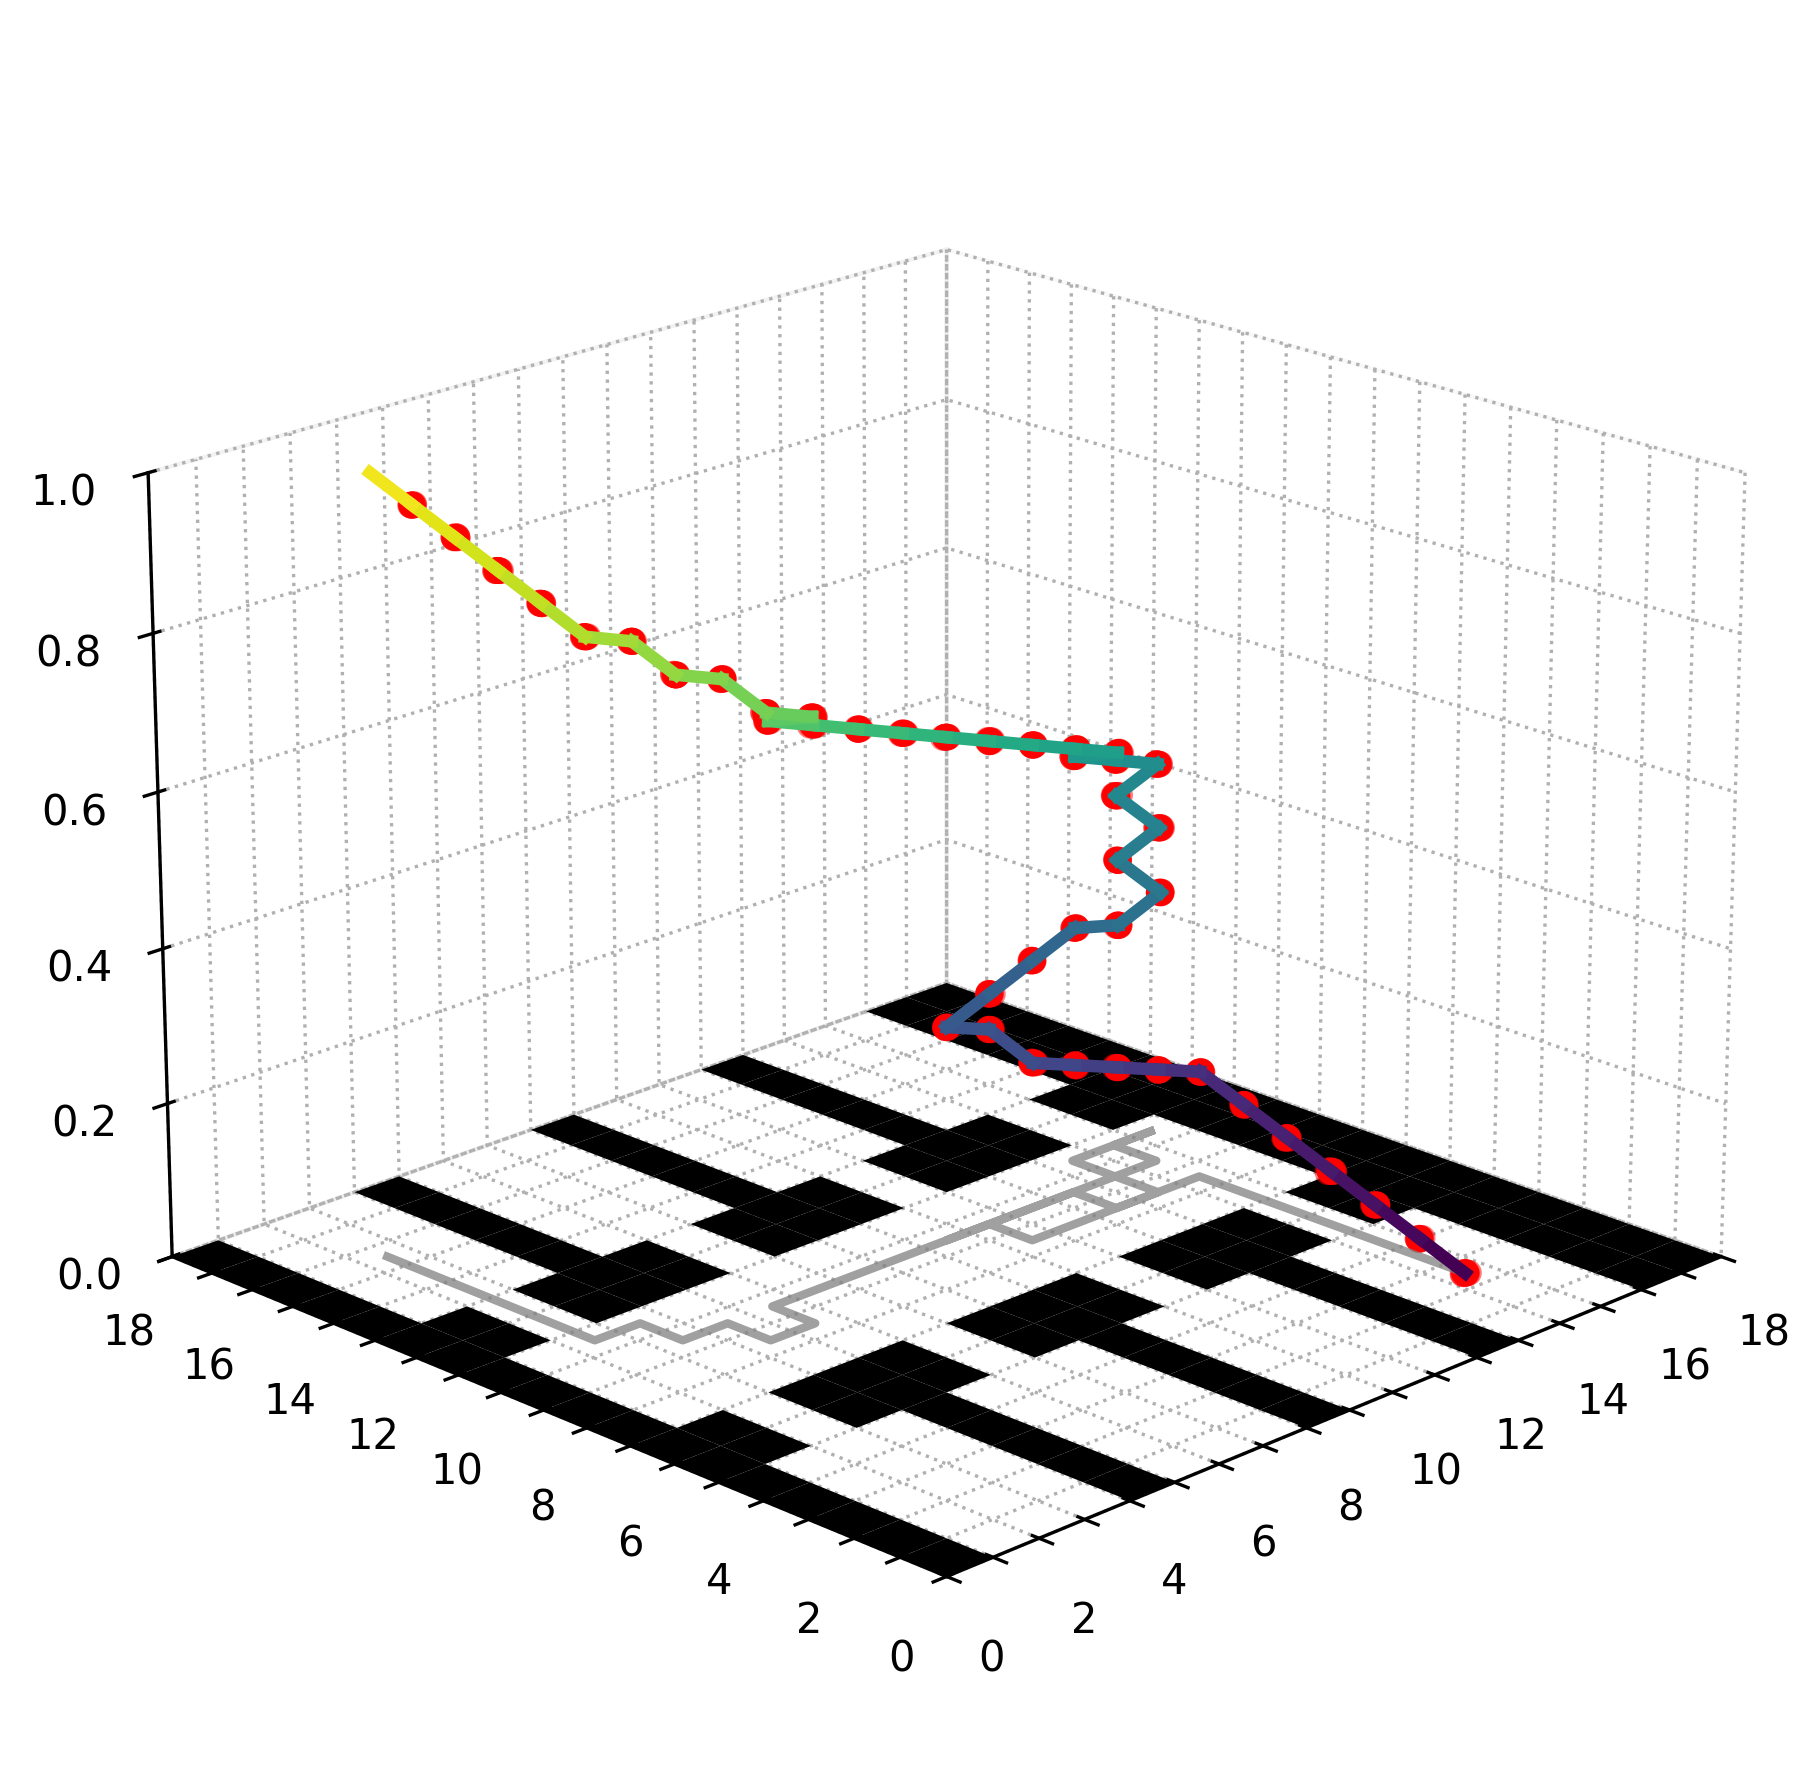

In [179]:
true_path = stored_protocol
x = [pos[0] for pos in true_path]
y = [pos[1] for pos in true_path]

# visualization 
fig = plt.figure(figsize=(10, 6), dpi=300)
ax = fig.add_subplot(111, projection="3d")

ax.set_xticks(np.arange(0, grid_size +1, 1))
ax.set_xticklabels([str(i) if i % 2 == 0 else "" for i in range(grid_size +1 )])
ax.set_yticks(np.arange(0, grid_size +1, 1))
ax.set_yticklabels([str(i) if i % 2 == 0 else "" for i in range(grid_size +1)])
ax.set_xlim(0, grid_size)
ax.set_ylim(0, grid_size)
ax.set_zlim(0, 1)

ax.set_box_aspect((1, 1, 0.75))
ax.view_init(elev=20, azim=-135)

ax.grid(True)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis._axinfo["grid"]["linestyle"] = ":"
    axis._axinfo["grid"]["linewidth"] = 0.8

ax.computed_zorder = False
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

for r, c in obstacles:
    verts = [[(r, c, 0), (r+1, c, 0), (r+1, c+1, 0), (r, c+1, 0)]]
    ax.add_collection3d(Poly3DCollection(verts, facecolors='black', alpha=1.0))

t = np.linspace(0, 1, len(x))

x_vis = np.array(x) + 0.5
y_vis = np.array(y) + 0.5

ax.plot(x_vis, y_vis, 0, color='gray', alpha=0.75, lw=2)

pass_1_entropy = np.array(results[0]['entropy_values'])
pass_2_entropy = np.array(results[1]['entropy_values'])
pass_3_entropy = np.array(results[2]['entropy_values'])

pass_3_entropy[0] = 0.0 # fix for alignment issue
entropy_3_values = np.abs(pass_3_entropy)

entropy_std = np.std([pass_1_entropy, pass_2_entropy, pass_3_entropy], axis=0)

max_std = np.max(entropy_std)
normalized_std = entropy_std / max_std if max_std > 0 else entropy_std

pass_1_result = results[0]
entropy_values = np.abs(np.array(pass_1_result['entropy_values']))

for i in range(len(x)-1):
     ax.plot(x_vis[i:i+2], y_vis[i:i+2], t[i:i+2], color=plt.cm.viridis(t[i]), lw=3)

for i in range(len(pass_3_entropy)):
    sigma_3 = entropy_3_values[i] * 2.0 
    eff_sigma_3 = max(sigma_3, 0.02) 
    nx3, ny3 = np.random.normal(0, eff_sigma_3, 15), np.random.normal(0, eff_sigma_3, 15)
    
    ax.scatter(x_vis[i] + nx3, y_vis[i] + ny3, t[i], 
               color='red', s=40, alpha=0.5, marker='o', edgecolors='none')


fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.98)
plt.show()

## Real-World Agent Deployment: Minimal Interactive Interface
**Deploy trained DRQN agent with real EMF measurements from hardware**

In [ ]:
class RealWorldAgent:
    """
    Deploys a trained DRQN agent on real EMF measurements instead of the simulator.

    Usage:
        agent = RealWorldAgent('../models/your_model.pkl')
        next_row, next_col = agent.step(probe_row, probe_col, emf_reading)
        agent.end_pass()   # when a pass is done, refines masking for the next one
        agent.reset()      # full reset back to pass 1
    """

    def __init__(self, model_path):
        self.agent = DRQNagent.load_complete(
            model_path,
            env_constructor=lambda: VoltageDistributionEnv(),
            feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
        )

        with open('../configuration/grid_configuration.json', 'r') as f:
            cfg = json.load(f)
        self.grid_size = cfg['gridSize']
        self.sigma = cfg['sigma']
        self.threshold = cfg['threshold']
        self.N = cfg['N']

        from belief_state import BeliefStateMap
        self.belief = BeliefStateMap(self.grid_size, self.sigma, self.threshold)
        self.masking = PassBasedMasking(self.grid_size)

        self.voltage_history = deque(
            [np.full((self.grid_size, self.grid_size), -1.0) for _ in range(self.N)],
            maxlen=self.N
        )

        self.hidden = None
        self.timestep = 0
        self.pass_num = 1
        self.trajectory = []
        self.entropy_history = []
        self.max_episode_length = 100

        print(f"RealWorldAgent initialized: grid {self.grid_size}x{self.grid_size}, sigma {self.sigma}, pass 1")

    def step(self, probe_row, probe_col, emf):
        """Process one real EMF measurement and return the next probe position."""
        probe_pos = (probe_row, probe_col)

        self.belief.prediction()
        self.belief.correction(emf, probe_pos)

        filtered_belief = self.belief.get_belief_distribution()
        entropy = self.belief.get_state_entropy()
        self.entropy_history.append(entropy)

        self.masking.record_step(self.timestep, probe_pos, emf, filtered_belief)
        self.trajectory.append({'t': self.timestep, 'pos': probe_pos, 'emf': emf})

        voltage_grid_current = np.full((self.grid_size, self.grid_size), -1.0)
        voltage_grid_current[probe_row, probe_col] = emf
        self.voltage_history.append(voltage_grid_current)

        obs = {
            'voltage': np.array([emf], dtype=np.float32),
            'probe position': np.array([probe_row, probe_col], dtype=np.int32),
            'voltage history': np.stack(list(self.voltage_history), axis=0).astype(np.float32),
            'time step': np.array([self.timestep / self.max_episode_length], dtype=np.float32),
        }

        # mask for the next position comes from the predicted belief, so predict,
        # read the mask, then restore the corrected belief for the following step
        belief_saved = self.belief.belief.copy()
        self.belief.prediction()
        action_mask = self.belief.get_action_mask()
        if self.pass_num > 1:
            action_mask = self.masking.get_refined_mask(self.timestep, action_mask)
        self.belief.belief = belief_saved

        q_values, self.hidden = extract_qvalues(self.agent, obs, self.hidden)

        masked_q = q_values.copy()
        mask_array = np.array(action_mask).flatten()
        masked_q[mask_array == 0] = -np.inf

        valid_indices = np.where(np.isfinite(masked_q))[0]
        if len(valid_indices) > 0:
            action = valid_indices[np.argmax(masked_q[valid_indices])]
        else:
            action = np.argmax(q_values)

        next_row = action // self.grid_size
        next_col = action % self.grid_size

        print(f"Pass {self.pass_num} step {self.timestep + 1}: probed ({probe_row}, {probe_col}), "
              f"EMF {emf:.4f}, entropy {entropy:.4f}, {len(valid_indices)}/{self.grid_size**2} valid moves")
        if emf >= 0.9:
            print(f"  high EMF - droplet likely at or near ({probe_row}, {probe_col})")
        print(f"  next probe: ({next_row}, {next_col})")

        self.timestep += 1

        return next_row, next_col

    def end_pass(self):
        """End the current pass and start the next one with refined masking."""
        self.masking.end_episode()
        self.masking.start_new_episode()

        avg_entropy = np.mean(self.entropy_history) if self.entropy_history else 0
        final_entropy = self.entropy_history[-1] if self.entropy_history else 0
        print(f"Pass {self.pass_num} complete: {self.timestep} steps, "
              f"avg entropy {avg_entropy:.4f}, final entropy {final_entropy:.4f}")
        print(f"Starting pass {self.pass_num + 1} with refined action masking")

        self.hidden = None
        self.timestep = 0
        self.pass_num += 1
        self.trajectory = []
        self.entropy_history = []

        self.belief.reset()
        self.voltage_history = deque(
            [np.full((self.grid_size, self.grid_size), -1.0) for _ in range(self.N)],
            maxlen=self.N
        )

    def reset(self):
        """Full reset - start over from pass 1."""
        self.hidden = None
        self.timestep = 0
        self.pass_num = 1
        self.trajectory = []
        self.entropy_history = []
        self.belief.reset()
        self.masking = PassBasedMasking(self.grid_size)
        self.voltage_history = deque(
            [np.full((self.grid_size, self.grid_size), -1.0) for _ in range(self.N)],
            maxlen=self.N
        )
        print("Full reset complete. Starting fresh from pass 1.")

    def get_entropy_history(self):
        """Return entropy values for the current pass."""
        return self.entropy_history.copy()

    def get_belief_distribution(self):
        """Return the current belief distribution."""
        return self.belief.get_belief_distribution()


def demo_real_world_agent(model_path, protocol_length=5, num_passes=3):
    """Run the real-world agent on dummy EMF values to sanity-check recurrency and multipass refinement."""
    print("Real-world agent demo")

    agent = RealWorldAgent(model_path)

    # low EMF = no droplet, high EMF = droplet nearby/found
    dummy_emfs = [0.05, 0.12, 0.08, 0.95, 0.02]

    for pass_num in range(1, num_passes + 1):
        print(f"\nStarting pass {pass_num}")

        current_row, current_col = agent.grid_size // 2, agent.grid_size // 2

        for step in range(protocol_length):
            emf = dummy_emfs[step % len(dummy_emfs)]
            next_row, next_col = agent.step(current_row, current_col, emf)
            current_row, current_col = next_row, next_col

        if pass_num < num_passes:
            agent.end_pass()

    print("\nDemo complete")

    return agent

## Initialize Trained in Simulation Agent for the Real World 

In [ ]:
real_agent = RealWorldAgent('../models/RecurrentDQN_Finalized_SciBot_V1.pkl')

**go through interaction steps**

In [ ]:
probe_row = int(input("Probe Row: "))
probe_col = int(input("Probe Column: "))
emf_reading = float(input("EMF Reading (0.0-1.0): "))

next_row, next_col = real_agent.step(probe_row, probe_col, emf_reading)

**end interaction steps when EMF >> than normally observed, as that is a sign that a reservoir is actuated and protocol has ended**

In [ ]:
real_agent.end_pass()

**full reset: run cell to start over from pass 1 with refinement held in memory** 

In [ ]:
real_agent.reset()